In [3]:
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
import numpy as np
from EDX import *
from utils import *
from utils_sofima import *
import hyperspy.api as hs
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import copy
from importlib import reload
from sklearn.preprocessing import MinMaxScaler

from skimage import data, img_as_float, feature
import tensorstore as ts
from scipy.stats import pearsonr
from datetime import datetime
import warnings
import pickle
from datetime import datetime

from itertools import repeat
import random
import logging
import exspy

/Users/aj/Desktop/work/virtualenvs/EDX2026/lib/python3.11/site-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazyComplexSignal1D` from `hyperspy._signals.complex_signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
/Users/aj/Desktop/work/virtualenvs/EDX2026/lib/python3.11/site-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
/Users/aj/Desktop/work/virtualenvs/EDX2026/lib/python3.11/site-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(


## Load data 

In [4]:
# Unaligned
with open(f'/Volumes/Microscopy4/qdotEDX/Preprocessed_EMEDX/unaligned/unaligned_20230523 1847 12-368Qdot 12000 x_20frames.pkl', 'rb') as file:
    tile_unaligned = pickle.load(file)


tile_unaligned.apply("crop", parameters = {"crop_idx": (slice(50,tile_unaligned.EDX_dim[0]-50),slice(50,tile_unaligned.EDX_dim[1]-50),slice(None,None,None))})
tile_unaligned.apply("binning", parameters={"dim": (974,974,250)})
tile_unaligned.apply("MeanFilterEDX", parameters={"kernel_size": 3})
print(tile_unaligned.summary())

# Aligned 
with open(f'/Volumes/Microscopy4/qdotEDX/Preprocessed_EMEDX/aligned/aligned_20230523 1847 12-368Qdot 12000 x_20frames.pkl', 'rb') as file:
    tile_aligned = pickle.load(file)


tile_aligned.apply("crop", parameters = {"crop_idx": (slice(50,tile_aligned.EDX_dim[0]-50),slice(50,tile_aligned.EDX_dim[1]-50),slice(None,None,None))})
tile_aligned.apply("binning", parameters={"dim": (974,974,250)})
tile_aligned.apply("MeanFilterEDX", parameters={"kernel_size": 3})
print(tile_aligned.summary())


# Aligned denoised
with open(f'/Volumes/Microscopy4/qdotEDX/Preprocessed_EMEDX/aligned_denoised/aligned_denoised_20230523 1847 12-368Qdot 12000 x_20frames.pkl', 'rb') as file:
    tile_aligned_denoised = pickle.load(file)


       operation                                         parameters  \
0           crop  crop_idx=(slice(None, None, None), slice(None,...   
1        binning                              dim=(2048, 2048, 250)   
2           crop  crop_idx=(slice(50, 1998, None), slice(50, 199...   
3        binning                                dim=(974, 974, 250)   
4  MeanFilterEDX                                      kernel_size=3   

     haadf size            EDX size notes  
0  (2048, 2048)  (2048, 2048, 4000)  None  
1  (2048, 2048)   (2048, 2048, 250)  None  
2  (1948, 1948)   (1948, 1948, 250)  None  
3    (974, 974)     (974, 974, 250)  None  
4    (974, 974)     (974, 974, 250)  None  
       operation                                         parameters  \
0           crop  crop_idx=(slice(None, None, None), slice(None,...   
1        binning                              dim=(2048, 2048, 250)   
2   sofima_align  hsi_stack_path=/Volumes/Microscopy4/tmp/202305...   
3           crop  crop_id

### Combine and give names

In [5]:
tiles = [tile_unaligned, tile_aligned, tile_aligned_denoised]
names = ['Raw','Aligned','Aligned & denoised']


# Optional: MinMax
for idx,tile in enumerate(tiles):
    tile.EDX = MinMax(tile.EDX)
    tiles[idx] = tile


### Lines, elements, energies

In [6]:
# define elements to plot, their x-ray lines and find the respective energy (in keV)
xray_lines = [['C', 'Ka'], ['N', 'Ka'], ['O', 'Ka'], ['P', 'Ka'], ['S', 'Ka'], ['Cl', 'Ka'], ['Ca', 'Ka'], ['Cu', 'Ka'],
              ['Cu', 'La'], ['Al', 'Ka'], ['Fe', 'Ka'], ['Fe', 'La'], ['Os', 'Ma'], ['Os', 'La'], ['Nd', 'La'],['Hf', 'La'], ['Cd','La']]

for idx, xray in enumerate(xray_lines):
    element, line = xray
    energy = exspy.material.elements[element]['Atomic_properties']['Xray_lines'][line]['energy (keV)']
    xray_lines[idx].append(energy)
    line_loc = np.argmin(np.abs(tiles[0].xray_energies-energy))
    xray_lines[idx].append(line_loc)

for x in xray_lines:
    print(f'Element: {x[0]:s}, line: {x[1]:s}, energy: {x[2]:.3f}, location: {x[3]:3d}')

Element: C, line: Ka, energy: 0.277, location:   3
Element: N, line: Ka, energy: 0.392, location:   4
Element: O, line: Ka, energy: 0.525, location:   6
Element: P, line: Ka, energy: 2.013, location:  25
Element: S, line: Ka, energy: 2.307, location:  28
Element: Cl, line: Ka, energy: 2.622, location:  32
Element: Ca, line: Ka, energy: 3.692, location:  46
Element: Cu, line: Ka, energy: 8.048, location: 100
Element: Cu, line: La, energy: 0.929, location:  11
Element: Al, line: Ka, energy: 1.486, location:  18
Element: Fe, line: Ka, energy: 6.404, location:  80
Element: Fe, line: La, energy: 0.705, location:   8
Element: Os, line: Ma, energy: 1.914, location:  23
Element: Os, line: La, energy: 8.911, location: 111
Element: Nd, line: La, energy: 5.230, location:  65
Element: Hf, line: La, energy: 7.899, location:  98
Element: Cd, line: La, energy: 3.134, location:  39


### Plots

### Cadmium full

AttributeError: 'Axes' object has no attribute 'set_'

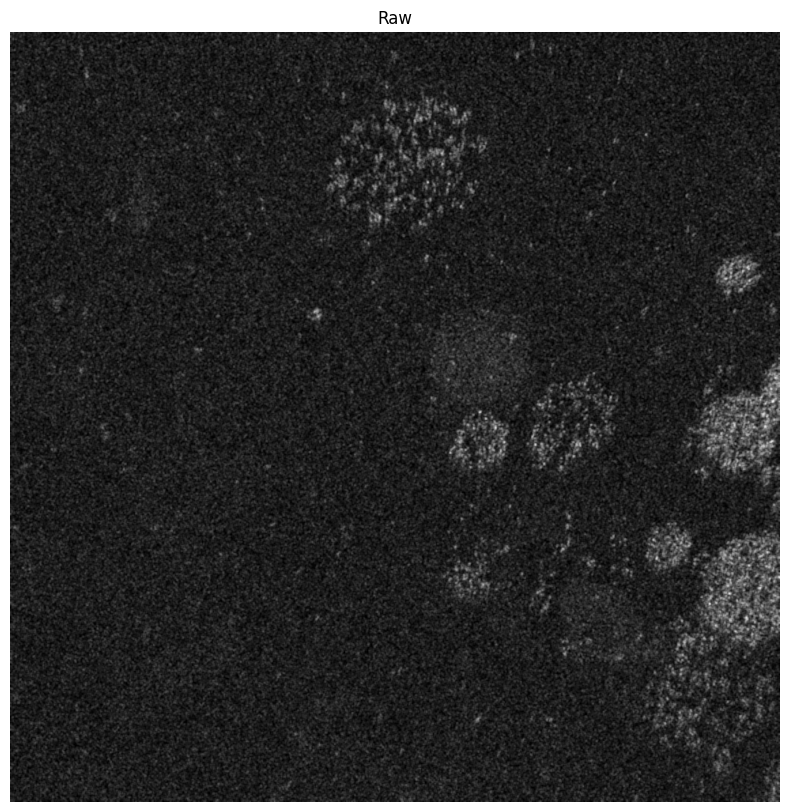

In [7]:
out_path = "/Volumes/Microscopy4/qdotEDX/Figures/Fig1"

for idx,tile in enumerate(tiles):
    f, ax = plt.subplots(figsize=(10,10))
    ax.imshow(tile.EDX[:,:,39], cmap='gray')
    ax.set_title(names[idx])
    ax.axis('OFF')
    ax.set_

    plt.savefig(os.path.join(out_path,f'Cd_{names[idx]}.png'),dpi=300)
    plt.savefig(os.path.join(out_path,f'Cd_{names[idx]}.svg'))

### Cadmium crop

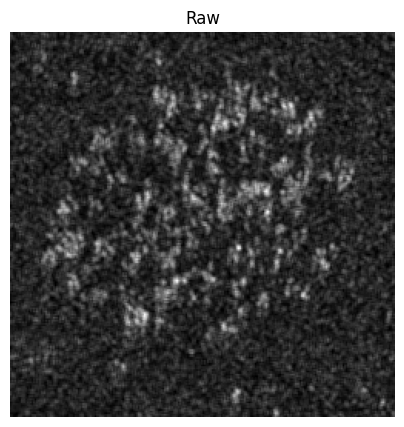

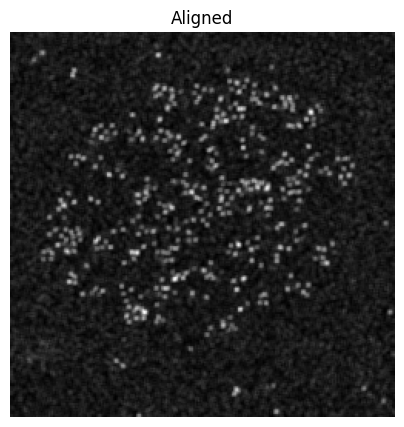

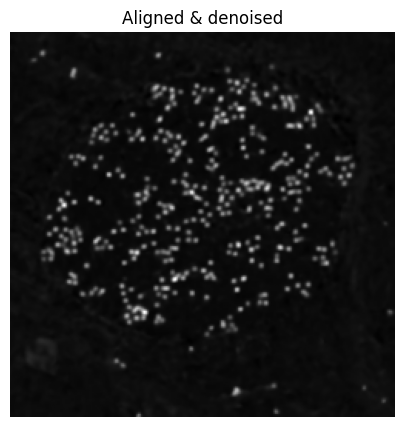

In [ ]:
zoom = (slice(50,300),slice(380,630))

for idx,tile in enumerate(tiles):
    f, ax = plt.subplots(figsize=(5,5))
    ax.imshow(tile.EDX[:,:,39][zoom], cmap='gray')
    ax.set_title(names[idx])
    ax.axis('OFF')

    plt.savefig(os.path.join(out_path,f'Cd_crop_{names[idx]}.png'),dpi=300)
    plt.savefig(os.path.join(out_path,f'Cd_crop_{names[idx]}.svg'))

## Spectral plot

### Export the cropped haadf for annotating the Qdots

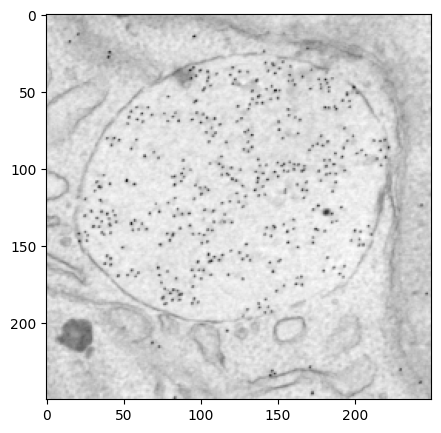

In [ ]:
## export cropped haadf
import tifffile as tf
zoom = (slice(50,300),slice(380,630))

f, ax = plt.subplots(figsize=(5,5))
ax.imshow(tiles[0].haadf[zoom],cmap='gray_r')
plt.show()
tf.imwrite('/Volumes/Microscopy4/qdotEDX/masks/crop_haadf.tiff',Normalize_uint8(tiles[0].haadf[zoom]))


### Load the annotated mask

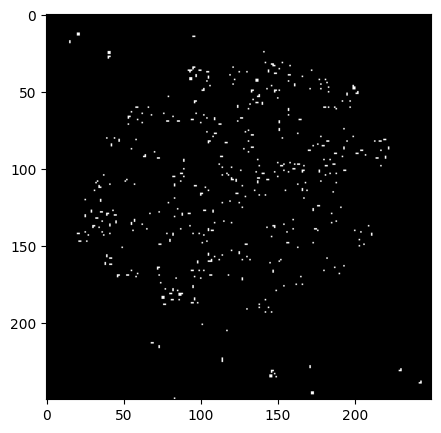

In [96]:
qdot_mask = tf.imread('/Volumes/Microscopy4/qdotEDX/masks/crop_haadf_mask.tif')
qdot_mask = (qdot_mask/255).astype('bool')

f, ax = plt.subplots(figsize=(5,5))
ax.imshow(qdot_mask,cmap='gray')
plt.show()

### Plot spectra without the mask

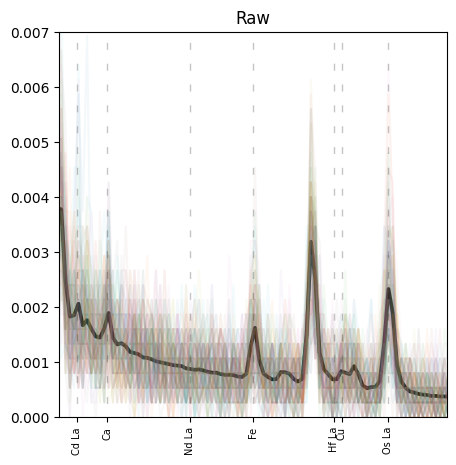

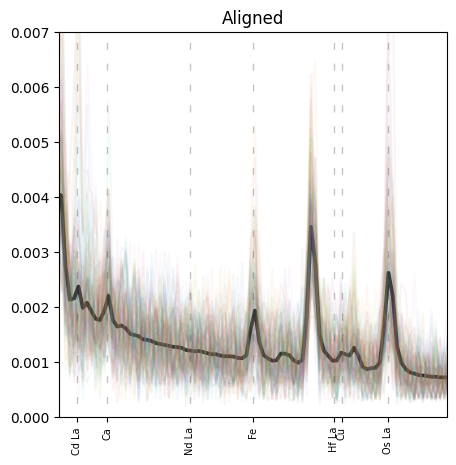

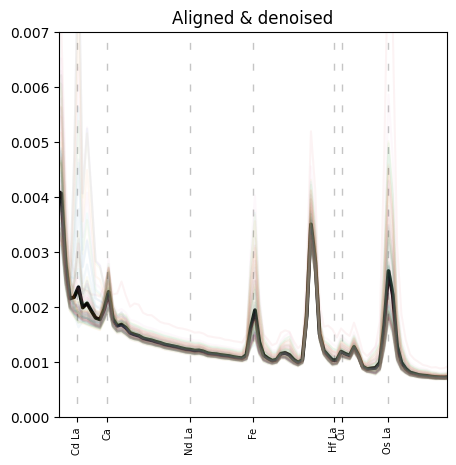

In [ ]:
zoom = (slice(50,300),slice(380,630),slice(None))
h = zoom[0].stop-zoom[0].start
w = zoom[1].stop-zoom[1].start

sample_idx = np.random.choice(h*w,100,replace=False)

x_start = 2.8
x_stop = 10
for idx,tile in enumerate(tiles):
    f, ax = plt.subplots(figsize=(5,5))
    ax.plot(tile.xray_energies,tile.EDX[:,:,:][zoom].mean(axis=(0,1)),c='k',linewidth=2.7)
    for i in sample_idx:
        ax.plot(tile.xray_energies,tile.EDX[:,:,:][zoom][np.unravel_index(i,(h,w))],alpha=0.05,linewidth=1.5)
    ax.set_title(names[idx])
    ax.set_xlim(x_start,x_stop)
    ax.set_ylim(0,0.007)
    #x.axis('OFF')

    # set xticks and add vertical lines at selected xray_lines
    xticks = []
    xlabels = []

    # for every selected x-ray, check if below the x-limit, proceed to add as tick and vline
    for xray in xray_lines:
        if xray[2] <= x_stop:
            if xray[2]>= x_start:
          
                xticks.append(xray[2])      #(np.argmin(np.abs(tile.xray_energies-xray[2])))
                if xray[1] == 'Ka':
                    xlabels.append(xray[0])
                else:
                    xlabels.append(xray[0] + ' ' + xray[1])
                plt.vlines(xray[2],
                        -0.5, 
                        tile.EDX_dim[2]-0.5, 
                        linestyle = (0,(5,10)), 
                        color = [0.1, 0.1, 0.1, 0.25], 
                        linewidth = 1)
    ax.set_xticks(xticks, xlabels, rotation = 90, size = 7) 
    
    


### Splot spectra in the cropped region with the masks

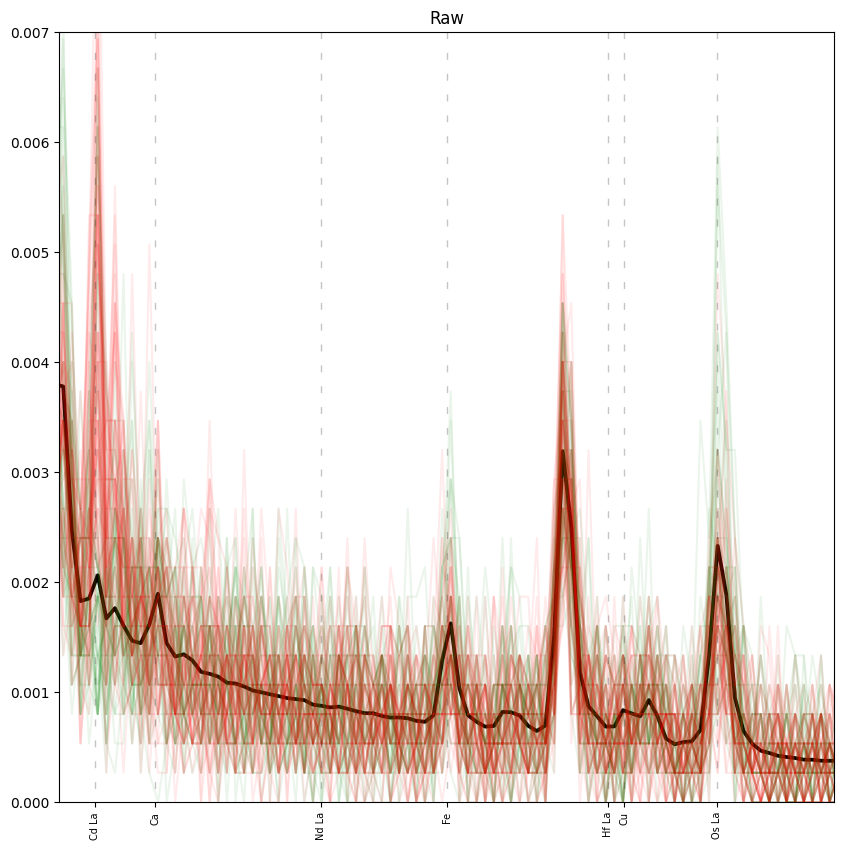

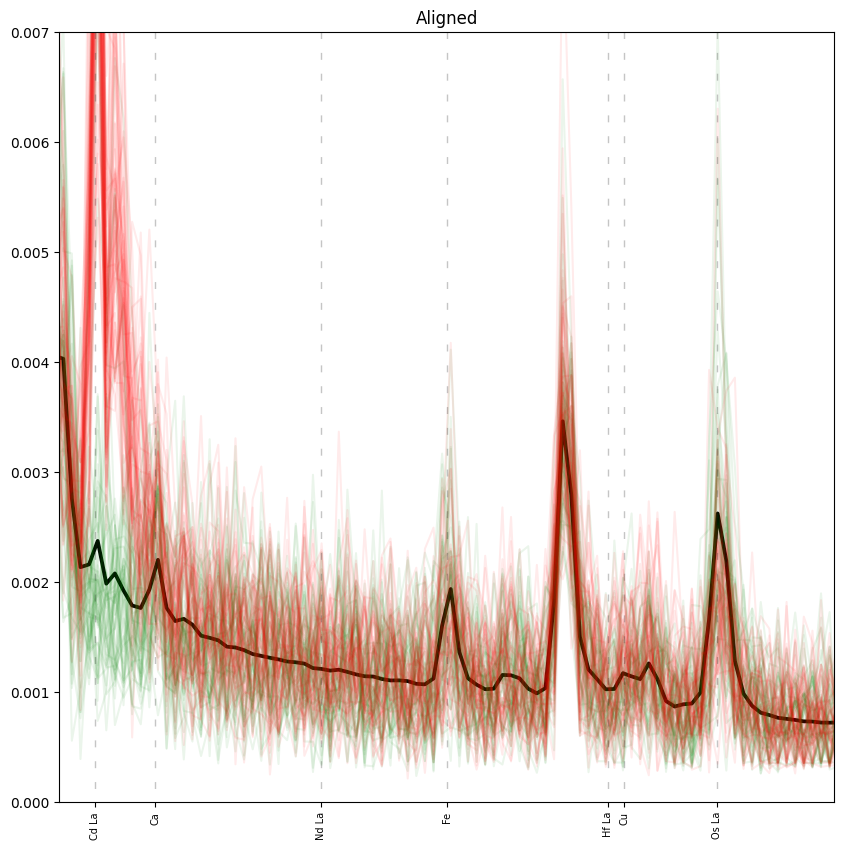

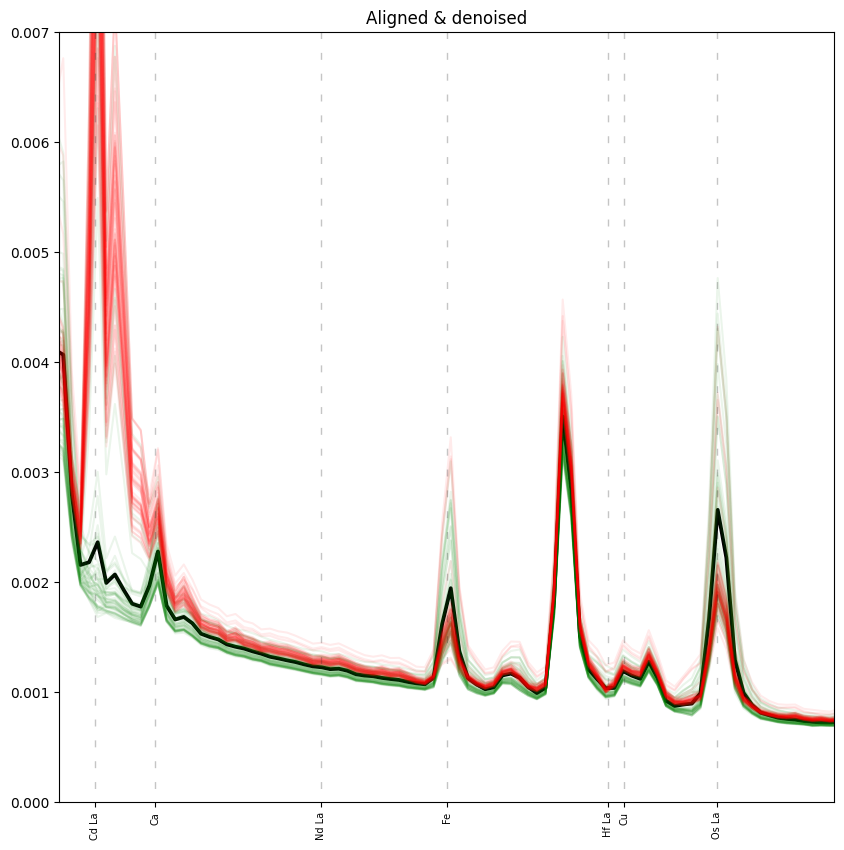

In [119]:
zoom = (slice(50,300),slice(380,630),slice(None))
h = zoom[0].stop-zoom[0].start
w = zoom[1].stop-zoom[1].start

# sample from background and qdots
sample_size = 50
sample_idx_bg = np.random.choice(np.where(~qdot_mask.ravel())[0],sample_size,replace=False)
sample_idx_qdot = np.random.choice(np.where(qdot_mask.ravel())[0],sample_size,replace=False)

x_start = 2.8
x_stop = 10
for idx,tile in enumerate(tiles):
    f, ax = plt.subplots(figsize=(10,10))
    ax.plot(tile.xray_energies,tile.EDX[:,:,:][zoom].mean(axis=(0,1)),c='k',linewidth=2.7)
    for i in sample_idx_bg:
        ax.plot(tile.xray_energies,tile.EDX[:,:,:][zoom][np.unravel_index(i,(h,w))],alpha=0.08,linewidth=1.5,c='g')
    for i in sample_idx_qdot:
        ax.plot(tile.xray_energies,tile.EDX[:,:,:][zoom][np.unravel_index(i,(h,w))],alpha=0.08,linewidth=1.5,c='r')
    ax.set_title(names[idx])
    ax.set_xlim(x_start,x_stop)
    ax.set_ylim(0,0.007)
    #x.axis('OFF')

    # set xticks and add vertical lines at selected xray_lines
    xticks = []
    xlabels = []

    # for every selected x-ray, check if below the x-limit, proceed to add as tick and vline
    for xray in xray_lines:
        if xray[2] <= x_stop:
            if xray[2]>= x_start:
          
                xticks.append(xray[2])      #(np.argmin(np.abs(tile.xray_energies-xray[2])))
                if xray[1] == 'Ka':
                    xlabels.append(xray[0])
                else:
                    xlabels.append(xray[0] + ' ' + xray[1])
                plt.vlines(xray[2],
                        -0.5, 
                        tile.EDX_dim[2]-0.5, 
                        linestyle = (0,(5,10)), 
                        color = [0.1, 0.1, 0.1, 0.25], 
                        linewidth = 1)
    ax.set_xticks(xticks, xlabels, rotation = 90, size = 7) 

    plt.savefig(os.path.join(out_path,f'Cd_cropSpectraMask_{names[idx]}.png'),dpi=300)
    plt.savefig(os.path.join(out_path,f'Cd_cropSpectraMask_{names[idx]}.svg'))